Level 2 Task 1: Regression Analysis

The objective of this task is to perform linear regression analysis on a stock dataset to predict one variable based on another.

Tools Used
Python
Pandas
Scikit-learn

Tasks Performed

Split the dataset into training and testing sets.

Fit a Linear Regression model using Scikit-Learn.

Interpret the model coefficients.

Evaluate the model using R-squared (R²) and Mean Squared Error (MSE).

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
import pandas as pd

df = pd.read_csv("Stock Prices Data Set.csv")

df.head()


,symbol,date,open,high,low,close,volume
0,AAL,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,2014-01-02,70.1100,70.2300,69.4800,69.8900,1148391


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 497472 entries, 0 to 497471
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   symbol  497472 non-null  str    
 1   date    497472 non-null  str    
 2   open    497461 non-null  float64
 3   high    497464 non-null  float64
 4   low     497464 non-null  float64
 5   close   497472 non-null  float64
 6   volume  497472 non-null  int64  
dtypes: float64(4), int64(1), str(2)
memory usage: 26.6 MB


In [6]:
df.columns

Index(['symbol', 'date', 'open', 'high', 'low', 'close', 'volume'], dtype='str')

In [7]:
print(df.columns)

Index(['symbol', 'date', 'open', 'high', 'low', 'close', 'volume'], dtype='str')


The dataset contains stock market information, including opening price, closing price, highest price, lowest price, trading volume, and date information.

The variables open and close were selected for regression analysis.

In [8]:
X = df[['open']]
y = df['close']

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Train-Test Split
The dataset was divided into training and testing sets.

Training Set: 80%
Testing Set: 20%
This allows the model to be trained on one portion of the data and evaluated on unseen data.

In [10]:
model = LinearRegression()

model.fit(X_train, y_train)

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [11]:
df[['open', 'close']].isnull().sum()

open     11
close     0
dtype: int64

In [12]:
df = df.dropna(subset=['open', 'close'])

In [13]:
X = df[['open']]
y = df['close']

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['open']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.02668
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


Before training the regression model, the dataset was checked for missing values.

Rows containing missing values in the selected variables (open and close) were removed to ensure data quality and prevent errors during model training.

In [15]:
y_pred = model.predict(X_test)

In [16]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 0.026677540332698868
Coefficient: 0.9998744981397042


The coefficient is very close to 1, indicating a strong positive relationship between the opening and closing stock prices. This means that for every one-unit increase in the opening price, the closing price increases by approximately one unit.

The small intercept value suggests that when the opening price is zero, the predicted closing price would be close to zero.

In [17]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("R-squared:", r2)
print("Mean Squared Error:", mse)

R-squared: 0.9997383343436389
Mean Squared Error: 2.7260823685319764


The R² score of 0.9997 indicates that the model explains approximately 99.97% of the variation in stock closing prices.

The low Mean Squared Error value demonstrates that the model's predictions are very close to the actual closing prices.

Conclusion
The regression model performed exceptionally well and successfully captured the relationship between stock opening and closing prices.

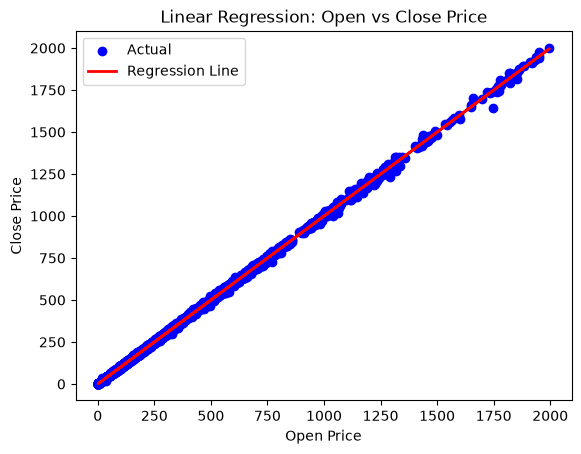

In [18]:
import matplotlib.pyplot as plt
 
plt.scatter(X_test, y_test, color='blue', label='Actual')
 
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Regression Line')
 
plt.xlabel("Open Price")
plt.ylabel("Close Price")
plt.title("Linear Regression: Open vs Close Price")
 
plt.legend()
 
plt.show()

A scatter plot and regression line were generated to visualize the relationship between stock opening prices and closing prices.

A strong positive linear relationship exists between the opening and closing prices.
Most data points lie very close to the regression line, indicating high prediction accuracy.
As the opening price increases, the closing price generally increases as well.

The regression model successfully captured the relationship between opening and closing stock prices. The close alignment between the data points and the regression line suggests that opening price is a strong predictor of closing price.